<center><font color='steelblue'> <font size = "6">CORPORACIÓN UNIVERSITARIA MINUTO DE DIOS </font></center><br>
<center><font color='steelblue'> <font size = "5,5">ESCUELA DE INGENIERÍA</font></center><br>
<center><font color='steelblue'> <font size = "5">PROGRAMA INGENIERÍA DE SISTEMAS - Modalidad Presencial</font></center><br>
<center><font color='steelblue'> <font size = "4">BASES DE DATOS MASIVAS</font></center><br>
<center><font color="yellow" size = "4" face = "small fonts">Proyecto Segundo Corte – Arquitectura distribuida, ETL y Mojo</font></center>

**Modalidad:** Aprendizaje Basado en Proyectos (ABP)
**Entregable:** `VarlanoaMoralesLauraVanesa_LozadaPachonNahomi_ProyectoBDM.ipynb`, ejecutable de principio a fin.

> **Propósito:** construir y demostrar una solución distribuida que integre tres nodos MongoDB, Docker, Mojo (Modular) y una base de datos relacional SQLite mediante un proceso ETL reproducible.

Python orquesta Docker, muestra resultados y dibuja las gráficas. La limpieza, la validación, la transformación y la carga relacional están en Mojo.


## 0. Datos del equipo

- **NRC:** 83355
- **Asignatura:** Bases de Datos Masivas
- **Docente:** Alonso Guevara Perez
- **Integrantes:**
  - Laura Vanesa Varlanoa Morales — ID 940120
  - Nahomi Lozada Pachon — ID 938752
- **Fecha:** 15 de octubre de 2026
- **Sistema operativo, Docker, Mojo y Python:** los imprime la celda de preparación

### Integridad académica

El código debe poder ser explicado por todos los integrantes. La inteligencia artificial puede utilizarse como apoyo para comprender, depurar o consultar documentación, pero no sustituye la comprensión.

**Regla:** aportes generados exclusivamente por IA, sin comprensión, adaptación, validación y explicación del estudiante, podrán recibir **0.0** en el componente correspondiente.


# 1. Contexto y reto

La organización dispone de tres fuentes JSON:

- `personas.json`
- `articulos.json`
- `ventas.json`

Cada fuente llega con basura mezclada con datos válidos: documentos como `@10@93@!65`, compradores como `q61@A!213A`, cantidades como `2x`, `9O` o `10K`, e identificadores repetidos que a veces solo cambian por ceros a la izquierda.

La información se distribuye en tres nodos MongoDB independientes, se procesa con Mojo y se integra en SQLite.

### Reto

> ¿Cómo diseñar e implementar una arquitectura distribuida que permita extraer, validar, transformar e integrar datos heterogéneos, garantizando integridad referencial y produciendo información útil para el análisis?

### Condición fundamental

El lenguaje de la lógica central de limpieza, validación y transformación es **Mojo de Modular**. No se usa Mojolicious ni Perl. Python no reemplaza esas funciones: prepara el entorno, extrae los documentos de MongoDB y presenta el resultado.


# 2. Arquitectura objetivo

```text
                    personas.json  articulos.json  ventas.json
                                    |
                                    v
                         red Docker bdm-red
                    /             |              \
                   v              v               v
           mongo_personas   mongo_articulos   mongo_ventas
           :27017           :27018            :27019
                    \             |              /
                     v            v             v
                    Mojo  limpiar / validar / etl
                    ejecutar_etl  carga SQLite
                                    |
                                    v
                         resultados/almacen.sqlite
                         PERSONAS  ARTICULOS  VENTAS
                                    |
                                    v
                         cuatro consultas y gráficas
```

No es un clúster con réplicas. Son tres contenedores, uno por dominio. El cuaderno, en el host, entra por localhost. Mojo corre en el contenedor `bdm-mojo:local` porque Mojo no tiene binario nativo para Windows; el contenedor es el servicio de procesamiento.


# 3. Modelo relacional de referencia

El cuaderno crea el DDL en `sql/esquema.sql` y Mojo lo ejecuta sobre una base SQLite nueva. No se entrega una base ya poblada.

| Tabla | Llave | Regla |
|---|---|---|
| PERSONAS | `numeroDocumento` | 6 a 12 dígitos |
| ARTICULOS | `idArticulo` | entero positivo |
| VENTAS | `idVenta` | `idComprador` referencia PERSONAS y `idArticulo` referencia ARTICULOS |

Las tablas son `STRICT`: un texto en una columna entera no entra. `precioArticulo` y `precioTotal` deben ser mayores que 0. `cantidadProductos` debe ser mayor que 0. El teléfono puede quedar NULL porque no participa en ninguna llave.


# 4. Preparación del entorno

El cuaderno crea la estructura y copia los JSON a `data/` sin modificar los originales. Las rutas salen de la carpeta del proyecto, no de una ruta fija del equipo.

```text
proyecto/
├── data/
├── mojo/src/  y  mojo/tests/
├── docker/
├── sql/
└── resultados/
```


In [1]:
from pathlib import Path
import importlib.util
import json
import platform
import shutil
import sqlite3
import subprocess
import sys
import time

def ubicar_proyecto():
    nombres = ("personas.json", "articulos.json", "ventas.json")
    candidatos = [Path.cwd(), *list(Path.cwd().parents)[:4]]
    for carpeta in candidatos:
        if all((carpeta / nombre).exists() for nombre in nombres):
            return carpeta
        if all((carpeta / "data" / nombre).exists() for nombre in nombres):
            return carpeta
    raise FileNotFoundError("No están personas.json, articulos.json y ventas.json junto al cuaderno.")

BASE = ubicar_proyecto()
DATA = BASE / "data"
MOJO_DIR = BASE / "mojo"
DOCKER_DIR = BASE / "docker"
SQL_DIR = BASE / "sql"
RESULTADOS = BASE / "resultados"
for carpeta in (DATA, MOJO_DIR / "src", MOJO_DIR / "tests", DOCKER_DIR, SQL_DIR, RESULTADOS):
    carpeta.mkdir(parents=True, exist_ok=True)

originales = []
for nombre in ("personas.json", "articulos.json", "ventas.json"):
    destino = DATA / nombre
    if (BASE / nombre).exists():
        shutil.copy2(BASE / nombre, destino)
        originales.append(BASE / nombre)
    elif not destino.exists():
        raise FileNotFoundError(nombre)

print("Directorio:", BASE)
print("Sistema operativo:", platform.platform())
print("Python:", sys.version.split()[0])
print("JSON copiados a data/, originales intactos:", len(originales))


Directorio: C:\Users\USUARIO\OneDrive - GENCELL PHARMA\Escritorio\Proyectosegudocorte\ProyectoSegundoCorte
Sistema operativo: Windows-11-10.0.26200-SP0
Python: 3.12.6
JSON copiados a data/, originales intactos: 3


## 4.1 Verificación de archivos y dependencias


In [2]:
requeridos = ["personas.json", "articulos.json", "ventas.json"]
for nombre in requeridos:
    ruta = DATA / nombre
    print(f"{nombre:20} ->", "OK" if ruta.exists() else "FALTA", ruta.name)

faltan = []
for modulo, paquete in {"pymongo": "pymongo", "pandas": "pandas", "matplotlib": "matplotlib"}.items():
    if importlib.util.find_spec(modulo) is None:
        faltan.append(paquete)
if faltan:
    print("Instalando:", ", ".join(faltan))
    subprocess.check_call([sys.executable, "-m", "pip", "install", *faltan])
else:
    print("Dependencias de Python listas.")

docker = subprocess.run(["docker", "version", "--format", "{{.Server.Version}}"], capture_output=True, text=True)
if docker.returncode != 0:
    raise RuntimeError("Docker no responde. Abre Docker Desktop y vuelve a ejecutar desde esta celda.\n" + docker.stderr)
print("Docker Engine:", docker.stdout.strip())


personas.json        -> OK personas.json
articulos.json       -> OK articulos.json
ventas.json          -> OK ventas.json
Dependencias de Python listas.


Docker Engine: 29.8.2


# 5. Perfilamiento inicial de los datos

Antes de transformar, el cuaderno cuenta registros, campos, vacíos, tipos y ejemplos inválidos. Los archivos originales no se modifican.


In [3]:
def cargar_json(nombre):
    with (DATA / nombre).open(encoding="utf-8") as archivo:
        return json.load(archivo)

personas = cargar_json("personas.json")
articulos = cargar_json("articulos.json")
ventas = cargar_json("ventas.json")
print("Personas :", len(personas))
print("Articulos:", len(articulos))
print("Ventas   :", len(ventas))


Personas : 10000
Articulos: 10000
Ventas   : 10000


In [4]:
from collections import Counter

def perfilar_registros(registros, nombre):
    print(f"\n--- {nombre}: {len(registros)} registros ---")
    if not registros:
        return
    for campo in registros[0]:
        vacios = sum(1 for fila in registros if fila.get(campo) in (None, ""))
        tipos = Counter(type(fila.get(campo)).__name__ for fila in registros)
        print(f"  {campo}: vacíos={vacios} tipos={dict(tipos)} ejemplo={registros[0][campo]!r}")

perfilar_registros(personas, "PERSONAS")
perfilar_registros(articulos, "ARTICULOS")
perfilar_registros(ventas, "VENTAS")



--- PERSONAS: 10000 registros ---
  numeroDocumento: vacíos=0 tipos={'str': 10000} ejemplo='@10@93@!65'
  nombres: vacíos=0 tipos={'str': 10000} ejemplo='Samuel'
  primerApellido: vacíos=0 tipos={'str': 10000} ejemplo='Roberts'
  segundoApellido: vacíos=0 tipos={'str': 10000} ejemplo='Sweeney'
  fechaNacimiento: vacíos=0 tipos={'str': 10000} ejemplo='1938-05-30'
  telefono: vacíos=0 tipos={'str': 10000} ejemplo='7546027921'
  direccion: vacíos=0 tipos={'str': 10000} ejemplo='8818 Evans Cove Apt. 968, North Hannahville, WY 96152'
  email: vacíos=0 tipos={'str': 10000} ejemplo='bondanthony@gmail.com'

--- ARTICULOS: 10000 registros ---
  idArticulo: vacíos=0 tipos={'str': 10000} ejemplo='358'
  nombreArticulo: vacíos=0 tipos={'str': 10000} ejemplo='Intel i9'
  precioArticulo: vacíos=0 tipos={'float': 10000} ejemplo=301.26
  cantidadArticulo: vacíos=0 tipos={'str': 10000} ejemplo='35'

--- VENTAS: 10000 registros ---
  idVenta: vacíos=0 tipos={'int': 10000} ejemplo=1
  idComprador: vacío

  idArticulo: vacíos=0 tipos={'int': 10000} ejemplo=2358
  cantidadProductos: vacíos=0 tipos={'str': 10000} ejemplo='2x'
  precioTotal: vacíos=0 tipos={'float': 10000} ejemplo=202.14


## 5.1 Análisis de calidad

| Fuente | Campo | Problema | Regla | Si no se puede recuperar |
|---|---|---|---|---|
| PERSONAS | numeroDocumento | letras y símbolos (`@10@93@!65`) | solo 6 a 12 dígitos | se descarta la persona: es la llave |
| PERSONAS | telefono | longitud o símbolos imposibles | 7 a 15 dígitos | la persona se conserva y el teléfono queda NULL |
| ARTICULOS | idArticulo | letras (`T474`, `2x`) o ceros a la izquierda | entero; `0668` y `668` son el mismo id | se descarta; no se adivina el número |
| ARTICULOS | precioArticulo | cero, negativo o no numérico | número mayor que 0 | se descarta el artículo |
| ARTICULOS | cantidadArticulo | letras mezcladas | entero mayor o igual que 0 | se descarta el artículo |
| VENTAS | idComprador | no es documento o no quedó en PERSONAS | formato válido y existencia | se descarta la venta |
| VENTAS | idArticulo | no es entero o no quedó en ARTICULOS | formato válido y existencia | se descarta la venta |
| VENTAS | cantidadProductos | `2x`, `9O`, `10K` | entero mayor que 0 | se descarta la venta |
| VENTAS | precioTotal | no positivo | número mayor que 0 | se descarta la venta |

`2x` no se convierte en 2. La letra puede ser basura o parte del dato, y no hay una regla segura. El precio total de la venta no se recalcula con el catálogo: el JSON no dice si hubo descuento, y completarlo sería inventar.


In [5]:
import re

def ejemplos_invalidos(filas, campo, regla, cantidad=4):
    vistos = []
    for fila in filas:
        if not regla(str(fila[campo]).strip()):
            vistos.append(fila[campo])
            if len(vistos) == cantidad:
                break
    return vistos

documento_re = re.compile(r"^\d{6,12}$")
digitos_re = re.compile(r"^\d+$")
print("documento:", ejemplos_invalidos(personas, "numeroDocumento", lambda v: documento_re.fullmatch(v)))
print("teléfono:", ejemplos_invalidos(personas, "telefono", lambda v: re.fullmatch(r"\d{7,15}", v)))
print("id artículo:", ejemplos_invalidos(articulos, "idArticulo", lambda v: digitos_re.fullmatch(v)))
print("cantidad artículo:", ejemplos_invalidos(articulos, "cantidadArticulo", lambda v: digitos_re.fullmatch(v)))
print("comprador:", ejemplos_invalidos(ventas, "idComprador", lambda v: documento_re.fullmatch(v)))
print("cantidad venta:", ejemplos_invalidos(ventas, "cantidadProductos", lambda v: digitos_re.fullmatch(v)))
print("Estos ejemplos se conservan en MongoDB. Mojo decide después cuáles entran a SQLite.")


documento: ['@10@93@!65', '67q0$A4A1q', '!5A0q@9$8$', '29A50q8087']
teléfono: ['422$9Aq9@1', '2@AA@2!18A', '$q$031944q', 'qA6Aq6$AA3']
id artículo: ['T474', '1o834', 'cO50', 'EXR63']
cantidad artículo: ['m18', '9rJ417', 'SBB462', 'W957']
comprador: ['q61@A!213A', '!@1$@8@1@8', 'q@9042@952', 'A488261q$4']
cantidad venta: ['2x', '9O', '10K', '8p']
Estos ejemplos se conservan en MongoDB. Mojo decide después cuáles entran a SQLite.


# 6. Docker: diseño de la infraestructura

| Servicio | Responsabilidad | Puerto en el host |
|---|---|---|
| `mongo_personas` | documentos de PERSONAS | 27017 |
| `mongo_articulos` | documentos de ARTICULOS | 27018 |
| `mongo_ventas` | documentos de VENTAS | 27019 |
| `bdm-mojo:local` | compila y ejecuta los `.mojo` | no queda escuchando: se invoca por corrida |

La base relacional es el archivo `resultados/almacen.sqlite`. SQLite no necesita otro contenedor y el cuaderno la crea desde cero. Los tres MongoDB comparten la red `bdm-red`, así que un contenedor resuelve el nombre de otro.

- **Red Docker:** `bdm-red`
- **Mongo PERSONAS:** `mongo_personas`, contenedor `bdm-mongo-personas`
- **Mongo ARTICULOS:** `mongo_articulos`, contenedor `bdm-mongo-articulos`
- **Mongo VENTAS:** `mongo_ventas`, contenedor `bdm-mongo-ventas`
- **Base relacional:** SQLite `resultados/almacen.sqlite`
- **Servicio Mojo:** imagen `bdm-mojo:local`, construida con `docker/Dockerfile.mojo`


In [6]:
def escribir(relativo, contenido):
    destino = BASE / relativo
    destino.parent.mkdir(parents=True, exist_ok=True)
    destino.write_text(contenido, encoding='utf-8', newline='\n')
    print('escrito', destino)

escribir('docker/docker-compose.yml', r'''name: bdm-mojo

services:
  mongo_personas:
    image: mongo:7
    container_name: bdm-mongo-personas
    ports:
      - "27017:27017"
    networks:
      - bdm-red
    volumes:
      - mongo_personas:/data/db
    healthcheck:
      test: ["CMD", "mongosh", "--quiet", "--eval", "db.adminCommand('ping').ok"]
      interval: 5s
      timeout: 5s
      retries: 30
    restart: unless-stopped

  mongo_articulos:
    image: mongo:7
    container_name: bdm-mongo-articulos
    ports:
      - "27018:27017"
    networks:
      - bdm-red
    volumes:
      - mongo_articulos:/data/db
    healthcheck:
      test: ["CMD", "mongosh", "--quiet", "--eval", "db.adminCommand('ping').ok"]
      interval: 5s
      timeout: 5s
      retries: 30
    restart: unless-stopped

  mongo_ventas:
    image: mongo:7
    container_name: bdm-mongo-ventas
    ports:
      - "27019:27017"
    networks:
      - bdm-red
    volumes:
      - mongo_ventas:/data/db
    healthcheck:
      test: ["CMD", "mongosh", "--quiet", "--eval", "db.adminCommand('ping').ok"]
      interval: 5s
      timeout: 5s
      retries: 30
    restart: unless-stopped

networks:
  bdm-red:
    name: bdm-red

volumes:
  mongo_personas:
  mongo_articulos:
  mongo_ventas:
''')

escribir('docker/Dockerfile.mojo', r'''FROM ubuntu:24.04

ENV DEBIAN_FRONTEND=noninteractive \
    PIP_BREAK_SYSTEM_PACKAGES=1 \
    PYTHONDONTWRITEBYTECODE=1

RUN apt-get update \
    && apt-get install -y --no-install-recommends \
        python3 \
        python3-pip \
        python3-venv \
        ca-certificates \
        curl \
    && rm -rf /var/lib/apt/lists/*

RUN python3 -m pip install --no-cache-dir uv \
    && python3 -m venv /opt/mojo-venv \
    && (uv pip install --python /opt/mojo-venv/bin/python mojo \
        || uv pip install --python /opt/mojo-venv/bin/python mojo \
            --index https://whl.modular.com/nightly/simple/ \
            --prerelease allow)

ENV PATH="/opt/mojo-venv/bin:${PATH}" \
    LD_LIBRARY_PATH="/usr/lib/x86_64-linux-gnu"

RUN apt-get update \
    && apt-get install -y --no-install-recommends libpython3.12 \
    && rm -rf /var/lib/apt/lists/*

WORKDIR /work
CMD ["mojo", "--version"]
''')

escribir('sql/esquema.sql', r'''PRAGMA foreign_keys = ON;

DROP TABLE IF EXISTS VENTAS;
DROP TABLE IF EXISTS ARTICULOS;
DROP TABLE IF EXISTS PERSONAS;

CREATE TABLE PERSONAS (
    numeroDocumento TEXT PRIMARY KEY,
    nombres TEXT NOT NULL,
    primerApellido TEXT NOT NULL,
    segundoApellido TEXT,
    fechaNacimiento TEXT,
    telefono TEXT,
    direccion TEXT,
    email TEXT
) STRICT;

CREATE TABLE ARTICULOS (
    idArticulo INTEGER PRIMARY KEY,
    nombreArticulo TEXT NOT NULL,
    precioArticulo REAL NOT NULL CHECK (precioArticulo > 0),
    cantidadArticulo INTEGER NOT NULL CHECK (cantidadArticulo >= 0)
) STRICT;

CREATE TABLE VENTAS (
    idVenta INTEGER PRIMARY KEY,
    idComprador TEXT NOT NULL REFERENCES PERSONAS (numeroDocumento),
    idArticulo INTEGER NOT NULL REFERENCES ARTICULOS (idArticulo),
    cantidadProductos INTEGER NOT NULL CHECK (cantidadProductos > 0),
    precioTotal REAL NOT NULL CHECK (precioTotal > 0)
) STRICT;

CREATE INDEX idx_ventas_comprador ON VENTAS (idComprador);
CREATE INDEX idx_ventas_articulo ON VENTAS (idArticulo);
''')

escribir('mojo/src/limpieza.mojo', r'''# Limpieza numerica. No adivina: 2x, 9O y 10K no se convierten.
# Mojo 1.1 no permite len(String) ni s[i]. Estos datos son ASCII,
# asi que la posicion se mide en bytes.


def _largo(texto: String) -> Int:
    return texto.byte_length()


def _caracter(texto: String, indice: Int) -> String:
    return String(texto[byte=indice])


def _cortar(texto: String, inicio: Int, fin: Int) -> String:
    return String(texto[byte=inicio:fin])


def recortar(valor: String) -> String:
    var inicio = 0
    var fin = _largo(valor)
    while inicio < fin:
        var caracter = _caracter(valor, inicio)
        if caracter != " " and caracter != "\t" and caracter != "\n" and caracter != "\r":
            break
        inicio += 1
    while fin > inicio:
        var caracter = _caracter(valor, fin - 1)
        if caracter != " " and caracter != "\t" and caracter != "\n" and caracter != "\r":
            break
        fin -= 1
    return _cortar(valor, inicio, fin)


def _es_digito(caracter: String) -> Bool:
    return caracter >= "0" and caracter <= "9"


def solo_digitos(valor: String) -> Bool:
    var texto = recortar(valor)
    if _largo(texto) == 0:
        return False
    var i = 0
    while i < _largo(texto):
        if not _es_digito(_caracter(texto, i)):
            return False
        i += 1
    return True


def quitar_ceros(texto: String) -> String:
    var i = 0
    var n = _largo(texto)
    while i < n - 1 and _caracter(texto, i) == "0":
        i += 1
    return _cortar(texto, i, n)


def limpiar_valor_numerico(valor: String) -> String:
    """Devuelve el numero canonico, o cadena vacia si el texto no es confiable.

    Acepta enteros y un solo punto decimal. Rechaza letras, simbolos,
    signos y mas de un punto. No transforma 2x, 9O ni 10K.
    """
    var texto = recortar(valor)
    if _largo(texto) == 0:
        return ""
    var punto = -1
    var i = 0
    var digitos = 0
    while i < _largo(texto):
        var caracter = _caracter(texto, i)
        if caracter == ".":
            if punto != -1:
                return ""
            punto = i
        elif _es_digito(caracter):
            digitos += 1
        else:
            return ""
        i += 1
    if digitos == 0:
        return ""
    if punto == -1:
        return quitar_ceros(texto)
    if punto == 0 or punto == _largo(texto) - 1:
        return ""
    var entero = quitar_ceros(_cortar(texto, 0, punto))
    var fraccion = _cortar(texto, punto + 1, _largo(texto))
    var j = 0
    while j < _largo(fraccion):
        if not _es_digito(_caracter(fraccion, j)):
            return ""
        j += 1
    return entero + "." + fraccion


def es_positivo(canonico: String) -> Bool:
    if _largo(canonico) == 0:
        return False
    var i = 0
    while i < _largo(canonico):
        var caracter = _caracter(canonico, i)
        if caracter != "0" and caracter != ".":
            return True
        i += 1
    return False


def es_entero_canonico(canonico: String) -> Bool:
    if _largo(canonico) == 0:
        return False
    var i = 0
    while i < _largo(canonico):
        if not _es_digito(_caracter(canonico, i)):
            return False
        i += 1
    return True
''')

escribir('mojo/src/validacion.mojo', r'''# Validacion de personas, articulos, ventas e integridad referencial.
from limpieza import (
    limpiar_valor_numerico,
    es_positivo,
    es_entero_canonico,
    solo_digitos,
    recortar,
)


def documento_valido(valor: String) -> Bool:
    var canonico = limpiar_valor_numerico(valor)
    if not es_entero_canonico(canonico):
        return False
    var n = canonico.byte_length()
    return n >= 6 and n <= 12


def telefono_valido(valor: String) -> Bool:
    var texto = recortar(valor)
    if not solo_digitos(texto):
        return False
    var n = texto.byte_length()
    return n >= 7 and n <= 15


def validar_persona(numero_documento: String, telefono: String) -> String:
    """ok | ok_telefono_nulo | documento_invalido.

    El telefono no es llave: si falla, la persona se conserva y el telefono queda vacio.
    Un documento dudoso se descarta porque contamina la llave primaria.
    """
    if not documento_valido(numero_documento):
        return "documento_invalido"
    if telefono_valido(telefono):
        return "ok"
    return "ok_telefono_nulo"


def validar_articulo(id_articulo: String, precio_articulo: String, cantidad_articulo: String) -> String:
    """ok | id_invalido | precio_invalido | cantidad_invalida."""
    var identificador = limpiar_valor_numerico(id_articulo)
    if not es_entero_canonico(identificador) or identificador == "0":
        return "id_invalido"
    var precio = limpiar_valor_numerico(precio_articulo)
    if not es_positivo(precio):
        return "precio_invalido"
    var cantidad = limpiar_valor_numerico(cantidad_articulo)
    if not es_entero_canonico(cantidad):
        return "cantidad_invalida"
    return "ok"


def limpiar_articulo(id_articulo: String, precio_articulo: String, cantidad_articulo: String) -> String:
    """Forma canonica id|precio|cantidad, o vacio si la validacion falla."""
    if validar_articulo(id_articulo, precio_articulo, cantidad_articulo) != "ok":
        return ""
    var identificador = limpiar_valor_numerico(id_articulo)
    var precio = limpiar_valor_numerico(precio_articulo)
    var cantidad = limpiar_valor_numerico(cantidad_articulo)
    return identificador + "|" + precio + "|" + cantidad


def validar_venta(
    id_comprador: String,
    id_articulo: String,
    cantidad_productos: String,
    precio_total: String,
) -> String:
    """ok | comprador_invalido | articulo_invalido | cantidad_invalida | precio_invalido.

    Esta funcion revisa la forma de los campos. La existencia del comprador
    y del articulo la confirma validar_integridad_referencial.
    """
    if not documento_valido(id_comprador):
        return "comprador_invalido"
    var articulo = limpiar_valor_numerico(id_articulo)
    if not es_entero_canonico(articulo) or articulo == "0":
        return "articulo_invalido"
    var cantidad = limpiar_valor_numerico(cantidad_productos)
    if not es_entero_canonico(cantidad) or not es_positivo(cantidad):
        return "cantidad_invalida"
    var total = limpiar_valor_numerico(precio_total)
    if not es_positivo(total):
        return "precio_invalido"
    return "ok"


def limpiar_venta(
    id_comprador: String,
    id_articulo: String,
    cantidad_productos: String,
    precio_total: String,
) -> String:
    if validar_venta(id_comprador, id_articulo, cantidad_productos, precio_total) != "ok":
        return ""
    var comprador = limpiar_valor_numerico(id_comprador)
    var articulo = limpiar_valor_numerico(id_articulo)
    var cantidad = limpiar_valor_numerico(cantidad_productos)
    var total = limpiar_valor_numerico(precio_total)
    return comprador + "|" + articulo + "|" + cantidad + "|" + total


def validar_integridad_referencial(
    id_comprador: String,
    id_articulo: String,
    comprador_existe: Bool,
    articulo_existe: Bool,
) -> Bool:
    """True solo si los ids sirven de llave y ambos extremos existen.

    ejecutar_etl calcula comprador_existe y articulo_existe contra las
    personas y los articulos ya aceptados. Si alguno falta, la venta no entra.
    """
    var comprador = limpiar_valor_numerico(id_comprador)
    var articulo = limpiar_valor_numerico(id_articulo)
    if not documento_valido(comprador):
        return False
    if not es_entero_canonico(articulo) or articulo == "0":
        return False
    return comprador_existe and articulo_existe
''')

escribir('mojo/src/etl.mojo', r'''# ETL: lee el extracto de MongoDB, valida en Mojo y carga SQLite.
from std.python import Python, PythonObject

from limpieza import limpiar_valor_numerico, recortar
from validacion import (
    validar_persona,
    validar_articulo,
    validar_venta,
    validar_integridad_referencial,
    telefono_valido,
)


def _leer_json(ruta: String) raises -> PythonObject:
    var json = Python.import_module("json")
    var pathlib = Python.import_module("pathlib")
    return json.loads(pathlib.Path(ruta).read_text(encoding="utf-8"))


def _como_texto(valor: PythonObject) raises -> String:
    var builtins = Python.import_module("builtins")
    var texto = String(builtins.str(valor))
    if texto == "None":
        return ""
    return recortar(texto)


def _fecha_o_vacio(valor: String) -> String:
    if valor.byte_length() != 10:
        return ""
    if String(valor[byte=4]) != "-" or String(valor[byte=7]) != "-":
        return ""
    var i = 0
    while i < 10:
        if i != 4 and i != 7:
            var caracter = String(valor[byte=i])
            if caracter < "0" or caracter > "9":
                return ""
        i += 1
    return valor


def ejecutar_etl(
    ruta_personas: String,
    ruta_articulos: String,
    ruta_ventas: String,
    ruta_resultados: String,
    ruta_esquema: String,
) raises -> String:
    """EXTRACT del JSON ya sacado de Mongo, VALIDATE, TRANSFORM y LOAD en SQLite.

    Python solo entra para leer JSON y hablar con sqlite3. Las reglas son Mojo.
    """
    var json = Python.import_module("json")
    var pathlib = Python.import_module("pathlib")
    var sqlite3 = Python.import_module("sqlite3")
    var builtins = Python.import_module("builtins")

    var crudas_personas = _leer_json(ruta_personas)
    var crudos_articulos = _leer_json(ruta_articulos)
    var crudas_ventas = _leer_json(ruta_ventas)

    var personas_ok = builtins.list()
    var articulos_ok = builtins.list()
    var ventas_ok = builtins.list()
    var vistos_documentos = builtins.set()
    var vistos_articulos = builtins.set()
    var vistos_ventas = builtins.set()

    var personas_descartadas = 0
    var telefonos_nulos = 0
    var articulos_descartados = 0
    var articulos_duplicados = 0
    var ventas_duplicadas = 0
    var venta_comprador = 0
    var venta_articulo = 0
    var venta_cantidad = 0
    var venta_precio = 0
    var venta_huerfana = 0

    var total_personas = Int(String(builtins.str(builtins.len(crudas_personas))))
    var i = 0
    while i < total_personas:
        var fila_persona = crudas_personas[i]
        var documento = _como_texto(fila_persona["numeroDocumento"])
        var telefono = _como_texto(fila_persona["telefono"])
        var estado_persona = validar_persona(documento, telefono)
        if estado_persona == "documento_invalido":
            personas_descartadas += 1
        else:
            var canonico_persona = limpiar_valor_numerico(documento)
            if vistos_documentos.__contains__(canonico_persona):
                personas_descartadas += 1
            else:
                vistos_documentos.add(canonico_persona)
                var tel = String("")
                if estado_persona == "ok" and telefono_valido(telefono):
                    tel = recortar(telefono)
                else:
                    telefonos_nulos += 1
                personas_ok.append(
                    Python.list(
                        canonico_persona,
                        _como_texto(fila_persona["nombres"]),
                        _como_texto(fila_persona["primerApellido"]),
                        _como_texto(fila_persona["segundoApellido"]),
                        _fecha_o_vacio(_como_texto(fila_persona["fechaNacimiento"])),
                        tel,
                        _como_texto(fila_persona["direccion"]),
                        _como_texto(fila_persona["email"]),
                    )
                )
        i += 1

    var total_articulos = Int(String(builtins.str(builtins.len(crudos_articulos))))
    i = 0
    while i < total_articulos:
        var fila_articulo = crudos_articulos[i]
        var identificador = _como_texto(fila_articulo["idArticulo"])
        var precio_articulo = _como_texto(fila_articulo["precioArticulo"])
        var cantidad_articulo = _como_texto(fila_articulo["cantidadArticulo"])
        var estado_articulo = validar_articulo(identificador, precio_articulo, cantidad_articulo)
        if estado_articulo != "ok":
            articulos_descartados += 1
        else:
            var canonico_articulo = limpiar_valor_numerico(identificador)
            if vistos_articulos.__contains__(canonico_articulo):
                articulos_duplicados += 1
            else:
                vistos_articulos.add(canonico_articulo)
                articulos_ok.append(
                    Python.list(
                        builtins.int(canonico_articulo),
                        _como_texto(fila_articulo["nombreArticulo"]),
                        builtins.float(limpiar_valor_numerico(precio_articulo)),
                        builtins.int(limpiar_valor_numerico(cantidad_articulo)),
                    )
                )
        i += 1

    var total_ventas = Int(String(builtins.str(builtins.len(crudas_ventas))))
    i = 0
    while i < total_ventas:
        var fila_venta = crudas_ventas[i]
        var venta = _como_texto(fila_venta["idVenta"])
        var comprador = _como_texto(fila_venta["idComprador"])
        var articulo = _como_texto(fila_venta["idArticulo"])
        var cantidad_venta = _como_texto(fila_venta["cantidadProductos"])
        var total_venta = _como_texto(fila_venta["precioTotal"])
        var estado_venta = validar_venta(comprador, articulo, cantidad_venta, total_venta)
        if estado_venta == "comprador_invalido":
            venta_comprador += 1
        elif estado_venta == "articulo_invalido":
            venta_articulo += 1
        elif estado_venta == "cantidad_invalida":
            venta_cantidad += 1
        elif estado_venta == "precio_invalido":
            venta_precio += 1
        else:
            var comprador_ok = limpiar_valor_numerico(comprador)
            var articulo_ok = limpiar_valor_numerico(articulo)
            var existe_comprador = False
            var existe_articulo = False
            if vistos_documentos.__contains__(comprador_ok):
                existe_comprador = True
            if vistos_articulos.__contains__(articulo_ok):
                existe_articulo = True
            if not validar_integridad_referencial(comprador_ok, articulo_ok, existe_comprador, existe_articulo):
                if not existe_comprador:
                    venta_comprador += 1
                else:
                    venta_articulo += 1
            elif vistos_ventas.__contains__(venta):
                ventas_duplicadas += 1
            else:
                vistos_ventas.add(venta)
                ventas_ok.append(
                    Python.list(
                        builtins.int(limpiar_valor_numerico(venta)),
                        comprador_ok,
                        builtins.int(articulo_ok),
                        builtins.int(limpiar_valor_numerico(cantidad_venta)),
                        builtins.float(limpiar_valor_numerico(total_venta)),
                    )
                )
        i += 1
    var destino = pathlib.Path(ruta_resultados)
    destino.mkdir(parents=True, exist_ok=True)
    var base = pathlib.Path(ruta_resultados) / "almacen.sqlite"
    if base.exists():
        base.unlink()
    var conexion = sqlite3.connect(String(base))
    conexion.execute("PRAGMA foreign_keys = ON")
    var esquema = pathlib.Path(ruta_esquema).read_text(encoding="utf-8")
    conexion.executescript(esquema)
    conexion.executemany(
        """
        INSERT INTO PERSONAS (
            numeroDocumento, nombres, primerApellido, segundoApellido,
            fechaNacimiento, telefono, direccion, email
        ) VALUES (?, ?, ?, ?, NULLIF(?, ''), NULLIF(?, ''), ?, ?)
        """,
        personas_ok,
    )
    conexion.executemany(
        """
        INSERT INTO ARTICULOS (idArticulo, nombreArticulo, precioArticulo, cantidadArticulo)
        VALUES (?, ?, ?, ?)
        """,
        articulos_ok,
    )
    conexion.executemany(
        """
        INSERT INTO VENTAS (idVenta, idComprador, idArticulo, cantidadProductos, precioTotal)
        VALUES (?, ?, ?, ?, ?)
        """,
        ventas_ok,
    )
    conexion.commit()
    conexion.close()

    var reporte = builtins.dict()
    reporte["personas_recibidas"] = total_personas
    reporte["personas_limpias"] = Int(String(builtins.str(builtins.len(personas_ok))))
    reporte["personas_descartadas"] = personas_descartadas
    reporte["telefonos_nulos"] = telefonos_nulos
    reporte["articulos_recibidos"] = total_articulos
    reporte["articulos_limpios"] = Int(String(builtins.str(builtins.len(articulos_ok))))
    reporte["articulos_descartados"] = articulos_descartados
    reporte["articulos_duplicados"] = articulos_duplicados
    reporte["ventas_recibidas"] = total_ventas
    reporte["ventas_integras"] = Int(String(builtins.str(builtins.len(ventas_ok))))
    reporte["ventas_duplicadas"] = ventas_duplicadas
    var causas = builtins.dict()
    causas["comprador_invalido_o_inexistente"] = venta_comprador
    causas["articulo_invalido_o_inexistente"] = venta_articulo
    causas["cantidad_no_confiable"] = venta_cantidad
    causas["precio_no_confiable"] = venta_precio
    causas["referencia_huerfana"] = venta_huerfana
    reporte["descartes_ventas"] = causas
    var ruta_reporte = pathlib.Path(ruta_resultados) / "reporte_etl.json"
    pathlib.Path(ruta_reporte).write_text(json.dumps(reporte, indent=2), encoding="utf-8")
    return String(json.dumps(reporte, indent=2))
''')

escribir('mojo/src/main.mojo', r'''from std.sys import argv

from etl import ejecutar_etl


def main() raises:
    var argumentos = argv()
    if len(argumentos) != 6:
        print("Uso: mojo run main.mojo personas.json articulos.json ventas.json resultados esquema.sql")
        raise Error("Faltan rutas del ETL")
    var resumen = ejecutar_etl(argumentos[1], argumentos[2], argumentos[3], argumentos[4], argumentos[5])
    print(resumen)
''')

escribir('mojo/tests/test_validaciones.mojo', r'''from limpieza import limpiar_valor_numerico, es_positivo
from validacion import (
    validar_persona,
    validar_articulo,
    limpiar_articulo,
    validar_venta,
    limpiar_venta,
    validar_integridad_referencial,
)


def afirmar(condicion: Bool, mensaje: String) raises:
    if not condicion:
        raise Error(mensaje)


def main() raises:
    # limpiar_valor_numerico: valido, invalido, vacio
    afirmar(limpiar_valor_numerico("0668") == "668", "0668 debe quedar 668")
    afirmar(limpiar_valor_numerico("2x") == "", "2x no se convierte")
    afirmar(limpiar_valor_numerico("  ") == "", "vacio no es numero")
    afirmar(limpiar_valor_numerico("9O") == "", "9O no se convierte")
    afirmar(limpiar_valor_numerico("10K") == "", "10K no se convierte")
    afirmar(limpiar_valor_numerico("301.26") == "301.26", "decimal confiable")
    afirmar(es_positivo("301.26"), "precio positivo")
    afirmar(not es_positivo("0.00"), "cero no es positivo")

    # validar_persona: valido, invalido, telefono nulo
    afirmar(validar_persona("12345678", "3001234567") == "ok", "persona valida")
    afirmar(validar_persona("@10@93@!65", "7546027921") == "documento_invalido", "documento sucio")
    afirmar(validar_persona("12345678", "422$9Aq9@1") == "ok_telefono_nulo", "telefono sucio no borra la persona")

    # articulos: valido, id invalido, precio invalido
    afirmar(validar_articulo("358", "301.26", "35") == "ok", "articulo valido")
    afirmar(validar_articulo("T474", "237.64", "18") == "id_invalido", "id con letras")
    afirmar(validar_articulo("15", "0", "3") == "precio_invalido", "precio cero")
    afirmar(validar_articulo("15", "10", "") == "cantidad_invalida", "cantidad vacia")
    afirmar(limpiar_articulo("0668", "10.5", "2") == "668|10.5|2", "limpia ceros a la izquierda")
    afirmar(limpiar_articulo("2x", "10", "2") == "", "no limpia un id ambiguo")

    # ventas: valida, cantidad ambigua, precio vacio
    afirmar(validar_venta("12345678", "358", "2", "202.14") == "ok", "venta valida")
    afirmar(validar_venta("12345678", "358", "9O", "10") == "cantidad_invalida", "9O no es cantidad")
    afirmar(validar_venta("q61@A!213A", "358", "2", "10") == "comprador_invalido", "comprador sucio")
    afirmar(limpiar_venta("", "1", "1", "1") == "", "venta vacia")

    # integridad: existe, comprador ausente, articulo ausente
    afirmar(validar_integridad_referencial("12345678", "358", True, True), "referencia existente")
    afirmar(
        not validar_integridad_referencial("0000000000", "358", False, True),
        "comprador inexistente",
    )
    afirmar(
        not validar_integridad_referencial("12345678", "99999", True, False),
        "articulo inexistente",
    )
    afirmar(
        not validar_integridad_referencial("@10@93@!65", "358", True, True),
        "id incompatible con el relacional",
    )
    print("Pruebas Mojo: 3 escenarios por funcion, todas pasaron.")
''')


escrito C:\Users\USUARIO\OneDrive - GENCELL PHARMA\Escritorio\Proyectosegudocorte\ProyectoSegundoCorte\docker\docker-compose.yml
escrito C:\Users\USUARIO\OneDrive - GENCELL PHARMA\Escritorio\Proyectosegudocorte\ProyectoSegundoCorte\docker\Dockerfile.mojo
escrito C:\Users\USUARIO\OneDrive - GENCELL PHARMA\Escritorio\Proyectosegudocorte\ProyectoSegundoCorte\sql\esquema.sql
escrito C:\Users\USUARIO\OneDrive - GENCELL PHARMA\Escritorio\Proyectosegudocorte\ProyectoSegundoCorte\mojo\src\limpieza.mojo
escrito C:\Users\USUARIO\OneDrive - GENCELL PHARMA\Escritorio\Proyectosegudocorte\ProyectoSegundoCorte\mojo\src\validacion.mojo
escrito C:\Users\USUARIO\OneDrive - GENCELL PHARMA\Escritorio\Proyectosegudocorte\ProyectoSegundoCorte\mojo\src\etl.mojo
escrito C:\Users\USUARIO\OneDrive - GENCELL PHARMA\Escritorio\Proyectosegudocorte\ProyectoSegundoCorte\mojo\src\main.mojo
escrito C:\Users\USUARIO\OneDrive - GENCELL PHARMA\Escritorio\Proyectosegudocorte\ProyectoSegundoCorte\mojo\tests\test_validacion

## 6.2 Levantamiento de contenedores

Esta celda construye la imagen de Mojo, levanta los tres MongoDB y guarda `docker compose config`, `docker compose ps` y un ping de `mongo_articulos` hacia `mongo_personas`.


In [7]:
compose_path = DOCKER_DIR / "docker-compose.yml"

def correr(comando, verificar=True):
    print("$", " ".join(comando))
    proceso = subprocess.run(comando, text=True, capture_output=True, encoding="utf-8", errors="replace")
    if (proceso.stdout or "").strip():
        print(proceso.stdout.strip())
    if (proceso.stderr or "").strip():
        print(proceso.stderr.strip())
    if verificar and proceso.returncode != 0:
        raise RuntimeError(f"Falló: {' '.join(comando)}")
    return proceso

print("docker compose config")
correr(["docker", "compose", "-f", str(compose_path), "config"])
correr(["docker", "build", "-t", "bdm-mojo:local", "-f", str(DOCKER_DIR / "Dockerfile.mojo"), str(DOCKER_DIR)])
correr(["docker", "compose", "-f", str(compose_path), "up", "-d"])

def esperar_sano(nombre, intentos=40):
    for _ in range(intentos):
        estado = subprocess.run(
            ["docker", "inspect", "-f", "{{.State.Health.Status}}", nombre],
            text=True, capture_output=True,
        )
        if estado.stdout.strip() == "healthy":
            print(nombre, "healthy")
            return
        time.sleep(3)
    raise TimeoutError(nombre)

for contenedor in ("bdm-mongo-personas", "bdm-mongo-articulos", "bdm-mongo-ventas"):
    esperar_sano(contenedor)

print("\ndocker compose ps")
correr(["docker", "compose", "-f", str(compose_path), "ps"])
print("\nRedes")
correr(["docker", "network", "ls", "--filter", "name=bdm-red"])
print("\nComunicación: mongo_articulos consulta a mongo_personas por el nombre de la red")
correr([
    "docker", "exec", "bdm-mongo-articulos",
    "mongosh", "--quiet", "--host", "mongo_personas", "--port", "27017",
    "--eval", "db.runCommand({ ping: 1 })",
])
version_mojo = correr(["docker", "run", "--rm", "bdm-mojo:local", "mojo", "--version"])
print("Versión de Mojo lista.")


docker compose config
$ docker compose -f C:\Users\USUARIO\OneDrive - GENCELL PHARMA\Escritorio\Proyectosegudocorte\ProyectoSegundoCorte\docker\docker-compose.yml config


name: bdm-mojo
services:
  mongo_articulos:
    container_name: bdm-mongo-articulos
    healthcheck:
      test:
        - CMD
        - mongosh
        - --quiet
        - --eval
        - db.adminCommand('ping').ok
      timeout: 5s
      interval: 5s
      retries: 30
    image: mongo:7
    networks:
      bdm-red: null
    ports:
      - mode: ingress
        target: 27017
        published: "27018"
        protocol: tcp
    restart: unless-stopped
    volumes:
      - type: volume
        source: mongo_articulos
        target: /data/db
        volume: {}
  mongo_personas:
    container_name: bdm-mongo-personas
    healthcheck:
      test:
        - CMD
        - mongosh
        - --quiet
        - --eval
        - db.adminCommand('ping').ok
      timeout: 5s
      interval: 5s
      retries: 30
    image: mongo:7
    networks:
      bdm-red: null
    ports:
      - mode: ingress
        target: 27017
        published: "27017"
        protocol: tcp
    restart: unless-stopped
   

#0 building with "desktop-linux" instance using docker driver

#1 [internal] load build definition from Dockerfile.mojo
#1 transferring dockerfile: 945B 0.1s done
#1 DONE 0.1s

#2 [internal] load metadata for docker.io/library/ubuntu:24.04
#2 DONE 1.4s

#3 [internal] load .dockerignore
#3 transferring context: 2B 0.0s done
#3 DONE 0.0s

#4 [1/5] FROM docker.io/library/ubuntu:24.04@sha256:534baea6a22c03a63003dbc8dbe78fe34bc0d7e595d9a9dc9834884ff530eb55
#4 resolve docker.io/library/ubuntu:24.04@sha256:534baea6a22c03a63003dbc8dbe78fe34bc0d7e595d9a9dc9834884ff530eb55 0.0s done
#4 DONE 0.1s

#5 [4/5] RUN apt-get update     && apt-get install -y --no-install-recommends libpython3.12     && rm -rf /var/lib/apt/lists/*
#5 CACHED

#6 [2/5] RUN apt-get update     && apt-get install -y --no-install-recommends         python3         python3-pip         python3-venv         ca-certificates         curl     && rm -rf /var/lib/apt/lists/*
#6 CACHED

#7 [3/5] RUN python3 -m pip install --no-cache-dir

Container bdm-mongo-ventas Running 
 Container bdm-mongo-personas Running 
 Container bdm-mongo-articulos Running
bdm-mongo-personas healthy


bdm-mongo-articulos healthy
bdm-mongo-ventas healthy

docker compose ps
$ docker compose -f C:\Users\USUARIO\OneDrive - GENCELL PHARMA\Escritorio\Proyectosegudocorte\ProyectoSegundoCorte\docker\docker-compose.yml ps


NAME                  IMAGE     COMMAND                  SERVICE           CREATED             STATUS                       PORTS
bdm-mongo-articulos   mongo:7   "docker-entrypoint.s…"   mongo_articulos   About an hour ago   Up About an hour (healthy)   0.0.0.0:27018->27017/tcp, [::]:27018->27017/tcp
bdm-mongo-personas    mongo:7   "docker-entrypoint.s…"   mongo_personas    About an hour ago   Up About an hour (healthy)   0.0.0.0:27017->27017/tcp, [::]:27017->27017/tcp
bdm-mongo-ventas      mongo:7   "docker-entrypoint.s…"   mongo_ventas      About an hour ago   Up About an hour (healthy)   0.0.0.0:27019->27017/tcp, [::]:27019->27017/tcp

Redes
$ docker network ls --filter name=bdm-red
NETWORK ID     NAME      DRIVER    SCOPE
3b38f20a96e0   bdm-red   bridge    local

Comunicación: mongo_articulos consulta a mongo_personas por el nombre de la red
$ docker exec bdm-mongo-articulos mongosh --quiet --host mongo_personas --port 27017 --eval db.runCommand({ ping: 1 })


{ ok: 1 }
$ docker run --rm bdm-mojo:local mojo --version


Mojo 1.1.0 (8189361e)
Versión de Mojo lista.


# 7. Carga de los JSON en MongoDB

Cada fuente entra a su nodo, sin limpiar. MongoDB conserva el documento tal como llegó, incluido el campo sucio. El `_id` técnico no se exporta hacia Mojo.


In [8]:
from pymongo import MongoClient

nodos = {
    "personas": (27017, "personas_db", "personas", personas),
    "articulos": (27018, "articulos_db", "articulos", articulos),
    "ventas": (27019, "ventas_db", "ventas", ventas),
}
clientes = {}
for nombre, (puerto, base, coleccion, filas) in nodos.items():
    cliente = MongoClient(f"mongodb://127.0.0.1:{puerto}", serverSelectionTimeoutMS=8000)
    cliente.admin.command("ping")
    cliente.drop_database(base)
    destino = cliente[base][coleccion]
    destino.insert_many(filas)
    print(f"{nombre}: {destino.count_documents({})} documentos en el puerto {puerto}")
    print("  ejemplo:", destino.find_one({}, {"_id": 0}))
    clientes[nombre] = destino

sucios = clientes["articulos"].count_documents({"idArticulo": {"$not": {"$regex": r"^\d+$"}}})
print("Artículos cuyo id no es numérico:", sucios)
print("Venta sucia:", clientes["ventas"].find_one({"cantidadProductos": {"$not": {"$regex": r"^\d+$"}}}, {"_id": 0}))


personas: 10000 documentos en el puerto 27017
  ejemplo: {'numeroDocumento': '@10@93@!65', 'nombres': 'Samuel', 'primerApellido': 'Roberts', 'segundoApellido': 'Sweeney', 'fechaNacimiento': '1938-05-30', 'telefono': '7546027921', 'direccion': '8818 Evans Cove Apt. 968, North Hannahville, WY 96152', 'email': 'bondanthony@gmail.com'}


articulos: 10000 documentos en el puerto 27018
  ejemplo: {'idArticulo': '358', 'nombreArticulo': 'Intel i9', 'precioArticulo': 301.26, 'cantidadArticulo': '35'}


ventas: 10000 documentos en el puerto 27019
  ejemplo: {'idVenta': 1, 'idComprador': 'q61@A!213A', 'idArticulo': 2358, 'cantidadProductos': '2x', 'precioTotal': 202.14}
Artículos cuyo id no es numérico: 4759
Venta sucia: {'idVenta': 1, 'idComprador': 'q61@A!213A', 'idArticulo': 2358, 'cantidadProductos': '2x', 'precioTotal': 202.14}


# 8. Mojo

Mojo de Modular ejecuta las funciones centrales. La CLI oficial usada aquí es `mojo --version` y `mojo run`.

| Módulo | Funciones |
|---|---|
| `mojo/src/limpieza.mojo` | `limpiar_valor_numerico` |
| `mojo/src/validacion.mojo` | `validar_persona`, `validar_articulo`, `limpiar_articulo`, `validar_venta`, `limpiar_venta`, `validar_integridad_referencial` |
| `mojo/src/etl.mojo` | `ejecutar_etl` |
| `mojo/src/main.mojo` | punto de entrada |
| `mojo/tests/test_validaciones.mojo` | tres escenarios por función: válido, inválido y vacío o no recuperable |

### Qué hace cada lenguaje

| Paso | Quién | Por qué |
|---|---|---|
| Docker, gráficas y tablas | Python | el enunciado lo permite en el cuaderno |
| Lectura de los tres MongoDB | Python | el driver de Mongo se usa desde Jupyter |
| Limpieza, validación, transformación y carga SQLite | Mojo | es el requisito central |
| JSON y sqlite3 dentro de Mojo | biblioteca de Python llamada por Mojo | Mojo no trae driver de Mongo ni de SQLite; la regla sigue siendo código Mojo |

Los archivos de la celda anterior son el código fuente. Esta celda solo muestra la versión y la ruta de los módulos.


In [9]:
print("Módulos:")
for ruta in sorted((MOJO_DIR / "src").glob("*.mojo")):
    print(" ", ruta.relative_to(BASE))
for ruta in sorted((MOJO_DIR / "tests").glob("*.mojo")):
    print(" ", ruta.relative_to(BASE))
correr(["docker", "run", "--rm", "bdm-mojo:local", "mojo", "--version"])


Módulos:
  mojo\src\etl.mojo
  mojo\src\limpieza.mojo
  mojo\src\main.mojo
  mojo\src\validacion.mojo
  mojo\tests\test_validaciones.mojo
$ docker run --rm bdm-mojo:local mojo --version


Mojo 1.1.0 (8189361e)


CompletedProcess(args=['docker', 'run', '--rm', 'bdm-mojo:local', 'mojo', '--version'], returncode=0, stdout='Mojo 1.1.0 (8189361e)\n', stderr='')

## 8.2 Pruebas unitarias de Mojo

Cada función central tiene dato válido, dato inválido y dato vacío o no recuperable. Si una afirmación falla, `mojo run` termina con error y el cuaderno se detiene.


In [10]:
correr([
    "docker", "run", "--rm",
    "-v", f"{BASE.resolve()}:/work",
    "-w", "/work",
    "bdm-mojo:local",
    "mojo", "run", "-I", "/work/mojo/src", "/work/mojo/tests/test_validaciones.mojo",
])


$ docker run --rm -v C:\Users\USUARIO\OneDrive - GENCELL PHARMA\Escritorio\Proyectosegudocorte\ProyectoSegundoCorte:/work -w /work bdm-mojo:local mojo run -I /work/mojo/src /work/mojo/tests/test_validaciones.mojo


Pruebas Mojo: 3 escenarios por funcion, todas pasaron.


CompletedProcess(args=['docker', 'run', '--rm', '-v', 'C:\\Users\\USUARIO\\OneDrive - GENCELL PHARMA\\Escritorio\\Proyectosegudocorte\\ProyectoSegundoCorte:/work', '-w', '/work', 'bdm-mojo:local', 'mojo', 'run', '-I', '/work/mojo/src', '/work/mojo/tests/test_validaciones.mojo'], returncode=0, stdout='Pruebas Mojo: 3 escenarios por funcion, todas pasaron.\n', stderr='')

# 9. ETL

```text
EXTRACT  ->  los tres nodos MongoDB, sin _id
PROFILE  ->  sección 5
VALIDATE ->  validar_persona, validar_articulo, validar_venta
TRANSFORM -> limpiar_valor_numerico y las funciones limpiar_*
REFERENTIAL CHECK -> validar_integridad_referencial
LOAD -> SQLite, solo filas aceptadas
VERIFY -> conteos, muestras y huérfanas
```

Cuando un valor no se puede transformar de forma confiable, no se corrige: se descarta el registro si el campo es llave, o se deja NULL si es el teléfono. Una venta solo entra si su comprador y su artículo ya fueron aceptados.

El orden de descarte de una venta es: forma del comprador, forma del artículo, forma de la cantidad, forma del precio y, al final, existencia en las tablas limpias.


In [11]:
def a_texto(valor):
    if isinstance(valor, bool):
        return str(valor)
    if isinstance(valor, float):
        texto = f"{valor:.10f}".rstrip("0").rstrip(".")
        return texto if texto else "0"
    if valor is None:
        return ""
    return str(valor).strip()

def exportar_desde_mongo(coleccion, nombre):
    filas = []
    for documento in coleccion.find({}, {"_id": 0}):
        filas.append({campo: a_texto(valor) for campo, valor in documento.items()})
    destino = RESULTADOS / nombre
    destino.write_text(json.dumps(filas, ensure_ascii=False), encoding="utf-8")
    print(nombre, len(filas), "documentos extraídos de MongoDB")
    return destino

extracto_personas = exportar_desde_mongo(clientes["personas"], "extract_personas.json")
extracto_articulos = exportar_desde_mongo(clientes["articulos"], "extract_articulos.json")
extracto_ventas = exportar_desde_mongo(clientes["ventas"], "extract_ventas.json")


extract_personas.json 10000 documentos extraídos de MongoDB


extract_articulos.json 10000 documentos extraídos de MongoDB
extract_ventas.json 10000 documentos extraídos de MongoDB


In [12]:
correr([
    "docker", "run", "--rm",
    "-v", f"{BASE.resolve()}:/work",
    "-w", "/work/mojo/src",
    "bdm-mojo:local",
    "mojo", "run", "main.mojo",
    "/work/resultados/extract_personas.json",
    "/work/resultados/extract_articulos.json",
    "/work/resultados/extract_ventas.json",
    "/work/resultados",
    "/work/sql/esquema.sql",
])
reporte = json.loads((RESULTADOS / "reporte_etl.json").read_text(encoding="utf-8"))
print("Reporte escrito por Mojo:")
print(json.dumps(reporte, indent=2, ensure_ascii=False))


$ docker run --rm -v C:\Users\USUARIO\OneDrive - GENCELL PHARMA\Escritorio\Proyectosegudocorte\ProyectoSegundoCorte:/work -w /work/mojo/src bdm-mojo:local mojo run main.mojo /work/resultados/extract_personas.json /work/resultados/extract_articulos.json /work/resultados/extract_ventas.json /work/resultados /work/sql/esquema.sql


{
  "personas_recibidas": 10000,
  "personas_limpias": 5014,
  "personas_descartadas": 4986,
  "telefonos_nulos": 2496,
  "articulos_recibidos": 10000,
  "articulos_limpios": 1055,
  "articulos_descartados": 7248,
  "articulos_duplicados": 1697,
  "ventas_recibidas": 10000,
  "ventas_integras": 478,
  "ventas_duplicadas": 0,
  "descartes_ventas": {
    "comprador_invalido_o_inexistente": 5039,
    "articulo_invalido_o_inexistente": 2035,
    "cantidad_no_confiable": 2448,
    "precio_no_confiable": 0,
    "referencia_huerfana": 0
  }
}
Reporte escrito por Mojo:
{
  "personas_recibidas": 10000,
  "personas_limpias": 5014,
  "personas_descartadas": 4986,
  "telefonos_nulos": 2496,
  "articulos_recibidos": 10000,
  "articulos_limpios": 1055,
  "articulos_descartados": 7248,
  "articulos_duplicados": 1697,
  "ventas_recibidas": 10000,
  "ventas_integras": 478,
  "ventas_duplicadas": 0,
  "descartes_ventas": {
    "comprador_invalido_o_inexistente": 5039,
    "articulo_invalido_o_inexistent

# 10. Base de datos relacional

Mojo ya creó `resultados/almacen.sqlite` con el esquema de `sql/esquema.sql`. Esta celda no reutiliza una base anterior: el ETL borra el archivo y lo vuelve a crear. `PRAGMA foreign_keys` queda activo en cada conexión.


In [13]:
db_path = RESULTADOS / "almacen.sqlite"
conexion = sqlite3.connect(db_path)
conexion.row_factory = sqlite3.Row
conexion.execute("PRAGMA foreign_keys = ON")
print("Base relacional:", db_path.name)
print((SQL_DIR / "esquema.sql").read_text(encoding="utf-8"))
for tabla in ("PERSONAS", "ARTICULOS", "VENTAS"):
    total = conexion.execute(f"SELECT COUNT(*) FROM {tabla}").fetchone()[0]
    print(tabla, total)


Base relacional: almacen.sqlite
PRAGMA foreign_keys = ON;

DROP TABLE IF EXISTS VENTAS;
DROP TABLE IF EXISTS ARTICULOS;
DROP TABLE IF EXISTS PERSONAS;

CREATE TABLE PERSONAS (
    numeroDocumento TEXT PRIMARY KEY,
    nombres TEXT NOT NULL,
    primerApellido TEXT NOT NULL,
    segundoApellido TEXT,
    fechaNacimiento TEXT,
    telefono TEXT,
    direccion TEXT,
    email TEXT
) STRICT;

CREATE TABLE ARTICULOS (
    idArticulo INTEGER PRIMARY KEY,
    nombreArticulo TEXT NOT NULL,
    precioArticulo REAL NOT NULL CHECK (precioArticulo > 0),
    cantidadArticulo INTEGER NOT NULL CHECK (cantidadArticulo >= 0)
) STRICT;

CREATE TABLE VENTAS (
    idVenta INTEGER PRIMARY KEY,
    idComprador TEXT NOT NULL REFERENCES PERSONAS (numeroDocumento),
    idArticulo INTEGER NOT NULL REFERENCES ARTICULOS (idArticulo),
    cantidadProductos INTEGER NOT NULL CHECK (cantidadProductos > 0),
    precioTotal REAL NOT NULL CHECK (precioTotal > 0)
) STRICT;

CREATE INDEX idx_ventas_comprador ON VENTAS (id

# 11. Carga final y verificación

Se contrastan los conteos de SQLite con el reporte de Mojo y con las 10 000 filas de cada fuente. La pérdida tiene que cuadrar.


In [14]:
import pandas as pd

def mostrar(titulo, consulta):
    print("\n" + titulo)
    tabla = pd.read_sql_query(consulta, conexion)
    print(tabla.to_string(index=False))
    return tabla

conteos = mostrar("Conteos", '''
    SELECT 'PERSONAS' AS tabla, COUNT(*) AS filas FROM PERSONAS
    UNION ALL SELECT 'ARTICULOS', COUNT(*) FROM ARTICULOS
    UNION ALL SELECT 'VENTAS', COUNT(*) FROM VENTAS
''')
mostrar("Muestra de personas", "SELECT * FROM PERSONAS LIMIT 3")
mostrar("Muestra de artículos", "SELECT * FROM ARTICULOS LIMIT 3")
mostrar("Muestra de ventas", "SELECT * FROM VENTAS LIMIT 3")

personas_sql = int(conteos.loc[conteos.tabla == "PERSONAS", "filas"].iloc[0])
articulos_sql = int(conteos.loc[conteos.tabla == "ARTICULOS", "filas"].iloc[0])
ventas_sql = int(conteos.loc[conteos.tabla == "VENTAS", "filas"].iloc[0])
assert personas_sql == reporte["personas_limpias"]
assert articulos_sql == reporte["articulos_limpios"]
assert ventas_sql == reporte["ventas_integras"]
assert reporte["personas_recibidas"] == reporte["personas_limpias"] + reporte["personas_descartadas"]
assert reporte["articulos_recibidos"] == reporte["articulos_limpios"] + reporte["articulos_descartados"] + reporte["articulos_duplicados"]
descartes = reporte["descartes_ventas"]
assert reporte["ventas_recibidas"] == reporte["ventas_integras"] + sum(descartes.values())
print("\nLos conteos cierran: cada registro recibido tiene un destino.")
print(f"De {reporte['personas_recibidas']} personas quedaron {personas_sql}. Teléfonos NULL: {reporte['telefonos_nulos']}.")
print(f"De {reporte['articulos_recibidos']} artículos quedaron {articulos_sql}.")
print(f"De {reporte['ventas_recibidas']} ventas quedaron {ventas_sql}.")



Conteos
    tabla  filas
 PERSONAS   5014
ARTICULOS   1055
   VENTAS    478

Muestra de personas
numeroDocumento nombres primerApellido segundoApellido fechaNacimiento   telefono                                            direccion                     email
      190252420   Aaron         Palmer            Khan      2016-05-24        NaN               9356 Burns Branch, Wardmouth, OK 05932          oliu@hotmail.com
     9710632840   Emily        Johnson         Garrett      1935-08-09        NaN              2268 Paul Camp, Michellemouth, NM 29782        jeremy92@gmail.com
     3631787826    Mark         Harper           White      1940-12-27 6032289435 047 Smith Ferry Apt. 797, Port Andrewmouth, MO 28667 michaelpeters@hotmail.com

Muestra de artículos
 idArticulo        nombreArticulo  precioArticulo  cantidadArticulo
          1      Deepcool Gammaxx          293.89              4220
          2 ASRock Phantom Gaming          226.81                12
          3          Asus ZenBoo

# 12. Pruebas de integridad referencial

Cada prueba muestra la consulta, el resultado y qué significa. Las inserciones de prueba se revierten: no modifican la carga.


In [15]:
print("Prueba A y B. Ventas cuyo comprador o artículo no existe. Debe dar 0 y 0.")
mostrar("Huérfanas", '''
    SELECT
        (SELECT COUNT(*) FROM VENTAS v
         LEFT JOIN PERSONAS p ON p.numeroDocumento = v.idComprador
         WHERE p.numeroDocumento IS NULL) AS sin_persona,
        (SELECT COUNT(*) FROM VENTAS v
         LEFT JOIN ARTICULOS a ON a.idArticulo = v.idArticulo
         WHERE a.idArticulo IS NULL) AS sin_articulo
''')

print("\nPrueba de inserción: venta 99999999 con comprador 0000000000.")
try:
    conexion.execute(
        "INSERT INTO VENTAS (idVenta, idComprador, idArticulo, cantidadProductos, precioTotal) VALUES (99999999, '0000000000', 1, 1, 1)"
    )
    conexion.commit()
    raise RuntimeError("La llave foránea no rechazó la venta.")
except sqlite3.IntegrityError as exc:
    conexion.rollback()
    print("Rechazada:", exc)

print("\nPrueba C. Duplicar un numeroDocumento existente.")
documento = conexion.execute("SELECT numeroDocumento FROM PERSONAS LIMIT 1").fetchone()[0]
try:
    conexion.execute(
        "INSERT INTO PERSONAS (numeroDocumento, nombres, primerApellido) VALUES (?, 'Duplicada', 'Prueba')",
        (documento,),
    )
    conexion.commit()
    raise RuntimeError("La llave primaria no rechazó el duplicado.")
except sqlite3.IntegrityError as exc:
    conexion.rollback()
    print("Rechazada:", exc)

print("\nPrueba D. NULL en un campo obligatorio.")
try:
    conexion.execute("INSERT INTO PERSONAS (numeroDocumento, nombres, primerApellido) VALUES ('123123', NULL, 'Prueba')")
    conexion.commit()
    raise RuntimeError("El NOT NULL no rechazó el nombre vacío.")
except sqlite3.IntegrityError as exc:
    conexion.rollback()
    print("Rechazada:", exc)

print("\nPrueba E. Texto en una columna entera de una tabla STRICT.")
try:
    conexion.execute(
        "INSERT INTO ARTICULOS (idArticulo, nombreArticulo, precioArticulo, cantidadArticulo) VALUES ('abc', 'Prueba', 10, 1)"
    )
    conexion.commit()
    raise RuntimeError("STRICT no rechazó el tipo incompatible.")
except sqlite3.IntegrityError as exc:
    conexion.rollback()
    print("Rechazada:", exc)

print("\nInterpretación: la base no solo quedó sin huérfanas. Impide crearlas después.")


Prueba A y B. Ventas cuyo comprador o artículo no existe. Debe dar 0 y 0.

Huérfanas
 sin_persona  sin_articulo
           0             0

Prueba de inserción: venta 99999999 con comprador 0000000000.
Rechazada: FOREIGN KEY constraint failed

Prueba C. Duplicar un numeroDocumento existente.
Rechazada: UNIQUE constraint failed: PERSONAS.numeroDocumento

Prueba D. NULL en un campo obligatorio.
Rechazada: NOT NULL constraint failed: PERSONAS.nombres

Prueba E. Texto en una columna entera de una tabla STRICT.
Rechazada: datatype mismatch

Interpretación: la base no solo quedó sin huérfanas. Impide crearlas después.


# 13. Consulta analítica 1 – Cinco artículos más vendidos

La métrica es la suma de `cantidadProductos`, no el número de facturas. El desempate es el id, para que el resultado no cambie entre ejecuciones.



Cinco artículos con más unidades
 idArticulo            nombreArticulo  unidades
         90         Apple MacBook Pro        30
        698 Razer BlackWidow Keyboard        24
        508          Canon EOS Camera        23
        869   Dell Ultrasharp Monitor        22
        227   Dell Ultrasharp Monitor        21


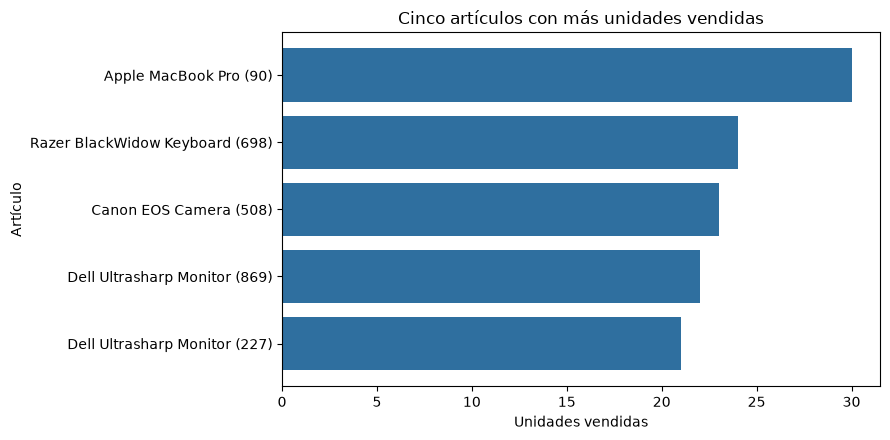

Interpretación: el primer puesto se define por unidades del id, no por el nombre. Un mismo nombre puede ser varios artículos.


In [16]:
%matplotlib inline
import matplotlib.pyplot as plt

top_articulos = mostrar("Cinco artículos con más unidades", '''
    SELECT a.idArticulo, a.nombreArticulo,
           SUM(v.cantidadProductos) AS unidades
    FROM VENTAS v
    JOIN ARTICULOS a ON a.idArticulo = v.idArticulo
    GROUP BY a.idArticulo, a.nombreArticulo
    ORDER BY unidades DESC, a.idArticulo
    LIMIT 5
''')
fig, ax = plt.subplots(figsize=(9, 4.5))
etiquetas = [f"{nombre} ({identificador})" for identificador, nombre in zip(top_articulos.idArticulo, top_articulos.nombreArticulo)]
ax.barh(etiquetas[::-1], list(top_articulos.unidades)[::-1], color="#2f6f9f")
ax.set_xlabel("Unidades vendidas")
ax.set_ylabel("Artículo")
ax.set_title("Cinco artículos con más unidades vendidas")
fig.tight_layout()
fig.savefig(RESULTADOS / "articulos_mas_vendidos.png", dpi=120)
plt.show()
print("Interpretación: el primer puesto se define por unidades del id, no por el nombre. Un mismo nombre puede ser varios artículos.")


# 14. Consulta analítica 2 – Cinco compradores con más compras

La métrica del ranking es el número de transacciones (`COUNT(*)`), no la cantidad de productos (`SUM(cantidadProductos)`). Las dos columnas se muestran para no mezclarlas. El desempate es el documento.



Cinco compradores con más transacciones
numeroDocumento          comprador  compras  productos
     1556086518 Cassandra Richmond        2          7
     2059134116   Darlene Crawford        2          8
     2103320162      Jennifer Kirk        2         15
     2232367853   Justin Whitehead        2          7
     2861844235     Lisa Hernandez        2          6


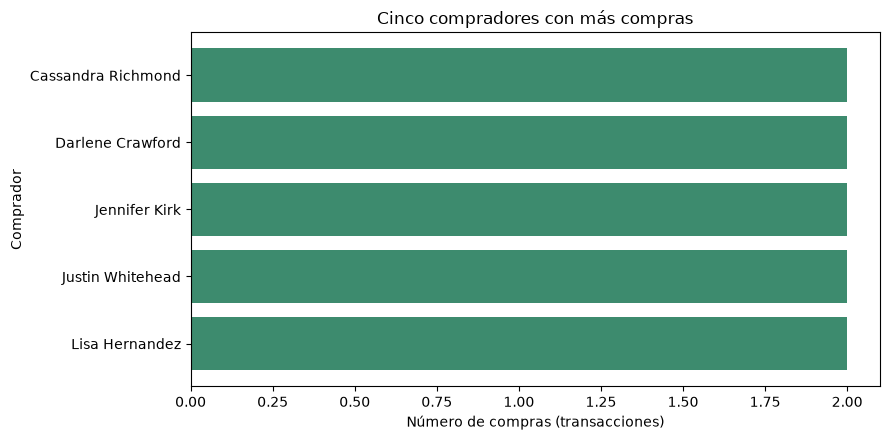

Interpretación: compras cuenta facturas. Productos suma las unidades de esas facturas. El gráfico usa compras.


In [17]:
top_compradores = mostrar("Cinco compradores con más transacciones", '''
    SELECT p.numeroDocumento,
           p.nombres || ' ' || p.primerApellido AS comprador,
           COUNT(*) AS compras,
           SUM(v.cantidadProductos) AS productos
    FROM VENTAS v
    JOIN PERSONAS p ON p.numeroDocumento = v.idComprador
    GROUP BY p.numeroDocumento, p.nombres, p.primerApellido
    ORDER BY compras DESC, p.numeroDocumento
    LIMIT 5
''')
fig, ax = plt.subplots(figsize=(9, 4.5))
etiquetas = list(top_compradores.comprador)[::-1]
ax.barh(etiquetas, list(top_compradores.compras)[::-1], color="#3d8b6e")
ax.set_xlabel("Número de compras (transacciones)")
ax.set_ylabel("Comprador")
ax.set_title("Cinco compradores con más compras")
fig.tight_layout()
fig.savefig(RESULTADOS / "compradores_mas_compras.png", dpi=120)
plt.show()
print("Interpretación: compras cuenta facturas. Productos suma las unidades de esas facturas. El gráfico usa compras.")


# 15. Consulta analítica 3 – Distribución de precios

El criterio de los cinco artículos es el de la consulta 13: los cinco con más unidades. Aquí se compara el precio de catálogo de esos mismos id. El eje horizontal es el artículo y el vertical es el precio, en las unidades monetarias que trae el JSON.


 idArticulo            nombreArticulo  precioArticulo
        698 Razer BlackWidow Keyboard          170.63
        227   Dell Ultrasharp Monitor          224.26
         90         Apple MacBook Pro          359.81
        508          Canon EOS Camera          392.06
        869   Dell Ultrasharp Monitor          430.20


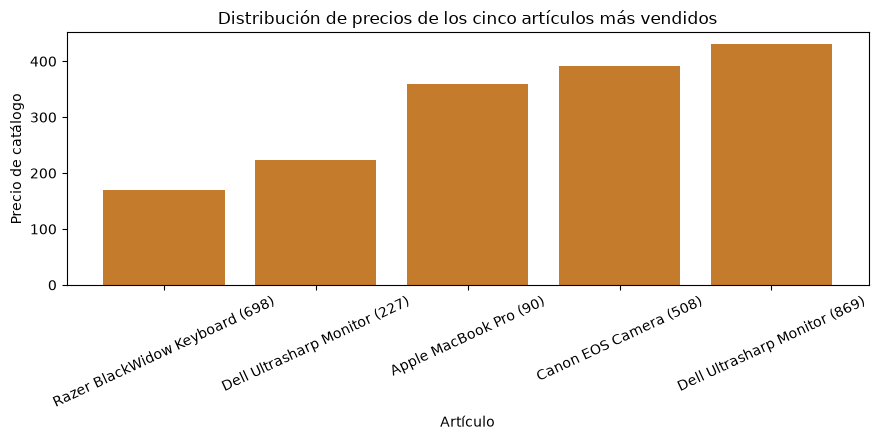

Interpretación: ser el más vendido en unidades no implica ser el más caro. Cada barra es un id, no un nombre agrupado.


In [18]:
ids = tuple(int(valor) for valor in top_articulos.idArticulo)
marcas = ",".join("?" for _ in ids)
precios = pd.read_sql_query(
    f'''
    SELECT idArticulo, nombreArticulo, precioArticulo
    FROM ARTICULOS
    WHERE idArticulo IN ({marcas})
    ORDER BY precioArticulo
    ''',
    conexion,
    params=ids,
)
print(precios.to_string(index=False))
fig, ax = plt.subplots(figsize=(9, 4.5))
etiquetas = [f"{nombre} ({identificador})" for identificador, nombre in zip(precios.idArticulo, precios.nombreArticulo)]
ax.bar(etiquetas, precios.precioArticulo, color="#c47b2b")
ax.set_ylabel("Precio de catálogo")
ax.set_xlabel("Artículo")
ax.set_title("Distribución de precios de los cinco artículos más vendidos")
ax.tick_params(axis="x", rotation=25)
fig.tight_layout()
fig.savefig(RESULTADOS / "distribucion_precios.png", dpi=120)
plt.show()
print("Interpretación: ser el más vendido en unidades no implica ser el más caro. Cada barra es un id, no un nombre agrupado.")


# 16. Consulta analítica 4 – Cinco artículos menos vendidos

La consulta incluye artículos que nunca aparecen en VENTAS. Esas unidades valen 0. Excluirlos ocultaría el inventario que no rotó. Como muchos pueden empatar en cero, el desempate es `idArticulo` ascendente: siempre salen los mismos cinco.



Cinco artículos con menos unidades, incluidos los de cero ventas
 idArticulo          nombreArticulo  unidades
          2   ASRock Phantom Gaming         0
          3            Asus ZenBook         0
          7     SeaSonic Focus Plus         0
         10 Dell Ultrasharp Monitor         0
         11      GoPro HERO9 Camera         0


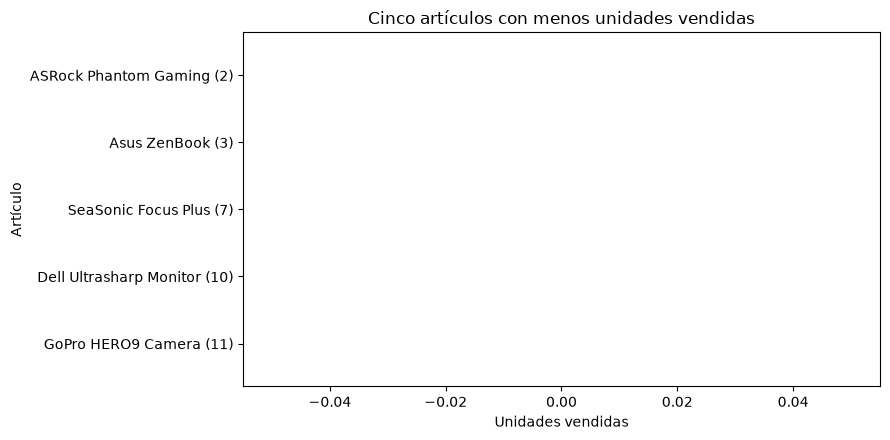

Interpretación: hay 677 artículos limpios con cero ventas. El gráfico enseña cinco de ese empate, no que solo esos cinco no se vendieron.


In [19]:
menos = mostrar("Cinco artículos con menos unidades, incluidos los de cero ventas", '''
    SELECT a.idArticulo, a.nombreArticulo,
           COALESCE(SUM(v.cantidadProductos), 0) AS unidades
    FROM ARTICULOS a
    LEFT JOIN VENTAS v ON v.idArticulo = a.idArticulo
    GROUP BY a.idArticulo, a.nombreArticulo
    ORDER BY unidades ASC, a.idArticulo ASC
    LIMIT 5
''')
fig, ax = plt.subplots(figsize=(9, 4.5))
etiquetas = [f"{nombre} ({identificador})" for identificador, nombre in zip(menos.idArticulo, menos.nombreArticulo)]
ax.barh(etiquetas[::-1], list(menos.unidades)[::-1], color="#8c4a4a")
ax.set_xlabel("Unidades vendidas")
ax.set_ylabel("Artículo")
ax.set_title("Cinco artículos con menos unidades vendidas")
fig.tight_layout()
fig.savefig(RESULTADOS / "articulos_menos_vendidos.png", dpi=120)
plt.show()
ceros = conexion.execute('''
    SELECT COUNT(*) FROM (
        SELECT a.idArticulo
        FROM ARTICULOS a
        LEFT JOIN VENTAS v ON v.idArticulo = a.idArticulo
        GROUP BY a.idArticulo
        HAVING COALESCE(SUM(v.cantidadProductos), 0) = 0
    )
''').fetchone()[0]
print(f"Interpretación: hay {ceros} artículos limpios con cero ventas. El gráfico enseña cinco de ese empate, no que solo esos cinco no se vendieron.")


# 17. Reproducibilidad

Esta celda borra la base generada y vuelve a ejecutar el ETL de Mojo. Los contenedores siguen arriba; el resultado relacional se reconstruye. Para repetir también Docker, en una terminal situada en la carpeta del proyecto:

```text
docker compose -f docker/docker-compose.yml down
docker compose -f docker/docker-compose.yml up -d
```

Luego se ejecuta el cuaderno otra vez. No hay rutas personales en el código.


In [20]:
conexion.close()
sqlite = RESULTADOS / "almacen.sqlite"
sqlite.unlink()
print("Base eliminada. Se reconstruye con Mojo.")
correr([
    "docker", "run", "--rm",
    "-v", f"{BASE.resolve()}:/work",
    "-w", "/work/mojo/src",
    "bdm-mojo:local",
    "mojo", "run", "main.mojo",
    "/work/resultados/extract_personas.json",
    "/work/resultados/extract_articulos.json",
    "/work/resultados/extract_ventas.json",
    "/work/resultados",
    "/work/sql/esquema.sql",
])
conexion = sqlite3.connect(sqlite)
conexion.execute("PRAGMA foreign_keys = ON")
reconstruido = conexion.execute("SELECT COUNT(*) FROM VENTAS").fetchone()[0]
print("Ventas después de reconstruir:", reconstruido)
assert reconstruido == ventas_sql
print("Python:", sys.version.split()[0])
correr(["docker", "--version"], verificar=False)
correr(["docker", "compose", "version"], verificar=False)
correr(["docker", "run", "--rm", "bdm-mojo:local", "mojo", "--version"])


Base eliminada. Se reconstruye con Mojo.
$ docker run --rm -v C:\Users\USUARIO\OneDrive - GENCELL PHARMA\Escritorio\Proyectosegudocorte\ProyectoSegundoCorte:/work -w /work/mojo/src bdm-mojo:local mojo run main.mojo /work/resultados/extract_personas.json /work/resultados/extract_articulos.json /work/resultados/extract_ventas.json /work/resultados /work/sql/esquema.sql


{
  "personas_recibidas": 10000,
  "personas_limpias": 5014,
  "personas_descartadas": 4986,
  "telefonos_nulos": 2496,
  "articulos_recibidos": 10000,
  "articulos_limpios": 1055,
  "articulos_descartados": 7248,
  "articulos_duplicados": 1697,
  "ventas_recibidas": 10000,
  "ventas_integras": 478,
  "ventas_duplicadas": 0,
  "descartes_ventas": {
    "comprador_invalido_o_inexistente": 5039,
    "articulo_invalido_o_inexistente": 2035,
    "cantidad_no_confiable": 2448,
    "precio_no_confiable": 0,
    "referencia_huerfana": 0
  }
}
Ventas después de reconstruir: 478
Python: 3.12.6
$ docker --version
Docker version 29.8.2, build 7fc2dff
$ docker compose version


Docker Compose version v5.5.1
$ docker run --rm bdm-mojo:local mojo --version


Mojo 1.1.0 (8189361e)


CompletedProcess(args=['docker', 'run', '--rm', 'bdm-mojo:local', 'mojo', '--version'], returncode=0, stdout='Mojo 1.1.0 (8189361e)\n', stderr='')

# 18. Defensa técnica

1. **¿Por qué tres nodos MongoDB?** Porque el enunciado pide un dominio por contenedor, no réplicas del mismo nodo. Personas, artículos y ventas se consultan y se pueden apagar por separado.
2. **¿Qué problema de calidad apareció?** Documentos con símbolos, teléfonos imposibles, ids como `T474` y cantidades `2x`, `9O` y `10K`.
3. **¿Qué regla se usó?** Entra lo que se puede verificar. La llave dudosa descarta el registro. El teléfono dudoso se vuelve NULL.
4. **¿Qué función Mojo transforma?** `limpiar_valor_numerico` canoniza el número. `validar_persona`, `validar_articulo` y `validar_venta` aplican la regla. `ejecutar_etl` las coordina.
5. **¿Cómo se garantiza la integridad?** Mojo solo inserta ventas cuyos extremos existen, y SQLite vuelve a impedirlo con las llaves foráneas.
6. **¿Qué pasa si una venta apunta a un artículo inexistente?** `validar_integridad_referencial` devuelve falso y la venta no se inserta. Si alguien la inserta después, SQLite la rechaza.
7. **¿Qué hace Python?** Docker, la carga y la extracción de MongoDB, las tablas, las gráficas y este cuaderno.
8. **¿Qué hace Mojo?** La limpieza, la validación, la decisión de carga y la escritura de SQLite.
9. **¿Cómo se reconstruye?** Borrar `almacen.sqlite` y volver a correr `mojo run main.mojo`, como hace la sección 17. Los JSON originales no cambian.
10. **¿Qué cambiar en una segunda versión?** Separar el contenedor de Mojo en una imagen publicada con la versión fijada, y agregar una fecha real de venta si el negocio la entrega.


# 19. Registro de uso de IA

| Herramienta | Uso | Aporte generado | Modificación realizada | Validación |
|---|---|---|---|---|
| Cursor, con el modelo Grok | Completar la guía oficial del proyecto: módulos Mojo, Docker, ETL y gráficas | Borrador del cuaderno, de los `.mojo` y del esquema SQLite | El equipo debe revisar las reglas de descarte, los nombres de las funciones y el resultado de cada consulta antes de sustentar | Ejecución de principio a fin del cuaderno y pruebas `mojo run` |

### Declaración

El equipo declara que puede explicar y defender el código presentado y que las herramientas de IA, si fueron utilizadas, fueron empleadas como apoyo y no como sustituto del aprendizaje.


# 20. Conclusiones

1. **Arquitectura distribuida.** Tres contenedores alcanzan para separar los dominios. La red `bdm-red` demuestra que se ven entre sí, y el cuaderno los integra sin copiar la lógica dentro de MongoDB.
2. **Calidad y ETL.** Descartar un valor ambiguo deja menos ventas, pero cada venta cargada tiene comprador, artículo, cantidad y total verificables. El dato sucio no desaparece: sigue en su nodo MongoDB.
3. **Mojo.** Las funciones pedidas viven en módulos y se ejecutan con la CLI. Python queda en la orquestación. En Windows hizo falta un contenedor porque Mojo no publica binario nativo.
4. **Ventajas y limitaciones de integrar MongoDB, Docker, Mojo y SQLite.** La ventaja es el reparto: MongoDB guarda la evidencia, Mojo aplica una regla única y SQLite impide una venta huérfana. La limitación es operativa: hay que levantar tres motores y un compilador, Mojo no habla con MongoDB por sí solo, y SQLite no muestra la concurrencia de un motor de servidor. Aun así, la cadena se puede borrar y volver a construir desde este cuaderno.
5. **Segunda versión.** Fijaría la etiqueta de la imagen de Mojo, mediría el tiempo de cada etapa y pediría al negocio una fecha de venta antes de hablar de series temporales.


# 21. Referencias

- Modular. Mojo documentation. https://docs.modular.com/mojo/
- Modular. Mojo CLI. https://docs.modular.com/mojo/cli/
- Docker Inc. Docker Compose documentation. https://docs.docker.com/compose/
- MongoDB Inc. MongoDB documentation. https://www.mongodb.com/docs/
- SQLite Consortium. SQLite documentation. https://www.sqlite.org/docs.html
- Matplotlib. Documentation. https://matplotlib.org/stable/index.html


# 22. Lista de comprobación antes de entregar

- [x] El notebook tiene los integrantes.
- [x] No existen rutas absolutas personales en el código.
- [x] Los tres JSON originales no fueron modificados.
- [x] Existen tres nodos MongoDB independientes.
- [x] Docker levanta la arquitectura.
- [x] Cada MongoDB contiene su fuente correspondiente.
- [x] Se realizó perfilamiento de datos.
- [x] Se documentaron problemas de calidad.
- [x] Las funciones centrales están implementadas en Mojo.
- [x] Existen pruebas de las funciones Mojo.
- [x] El ETL está documentado.
- [x] Se creó la base relacional desde cero.
- [x] Se validaron PK y FK.
- [x] Se comprobaron registros huérfanos.
- [x] Se realizaron las cuatro consultas analíticas.
- [x] Se generaron los gráficos.
- [x] Cada resultado tiene interpretación.
- [x] Se registró el uso de IA.
- [x] El notebook se ejecuta de principio a fin.
- [x] Las conclusiones responden la integración de MongoDB, Docker, Mojo y SQLite.

# ENTREGABLE

## `VarlanoaMoralesLauraVanesa_LozadaPachonNahomi_ProyectoBDM.ipynb`

El cuaderno contiene código, resultados, evidencias, análisis y conclusiones. Al ejecutarse escribe Docker, Mojo, SQL y la base.
